# Task 2: Predictive Analysis using Machine Learning
**EliteTech Intern – Data Analytics Internship**

**Objective:** Build a **classification model** that predicts whether a telecom customer will **churn** (cancel their service), and demonstrate **feature selection, model training and evaluation**.

**Dataset:** [IBM Telco Customer Churn](https://github.com/IBM/telco-customer-churn-on-icp4d). It has 7,043 customers and 21 columns: demographics, the services each customer uses, account details, and whether they churned.

**Why it matters:** Winning a new customer costs much more than keeping an existing one. A churn model lets the business find at-risk customers early and target them with retention offers.

**Contents**
1. Load and understand the data
2. Data cleaning
3. Exploratory data analysis (EDA)
4. Feature engineering and encoding
5. Feature selection
6. Model training (3 models + cross-validation)
7. Model evaluation
8. Hyperparameter tuning of the best model
9. Business insights

In [1]:
# Import libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             RocCurveDisplay, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # fixed seed so the results can be reproduced

## 1. Load and understand the data

In [2]:
df = pd.read_csv("../data/telco_churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 2. Data cleaning
`TotalCharges` is stored as text, and brand-new customers (tenure = 0) have a blank value. We convert the column to numbers and fill the blanks with 0, because those customers have not been billed yet.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")
print("Blank TotalCharges:", df["TotalCharges"].isna().sum())
print("Tenure of those rows:", df.loc[df["TotalCharges"].isna(), "tenure"].unique())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# customerID is just an identifier and has no predictive value
df = df.drop(columns="customerID")

# Convert the target to 1 = churned, 0 = stayed
df["Churn"] = (df["Churn"] == "Yes").astype(int)

# Without the ID column a few rows look identical; they are different customers with the
# same profile, so we keep them.
print("Identical-looking rows (kept):", df.duplicated().sum())
print("Missing values left:", df.isna().sum().sum())

Blank TotalCharges: 11
Tenure of those rows: [0]
Identical-looking rows (kept): 22
Missing values left: 0


## 3. Exploratory data analysis

Overall churn rate: 26.5%


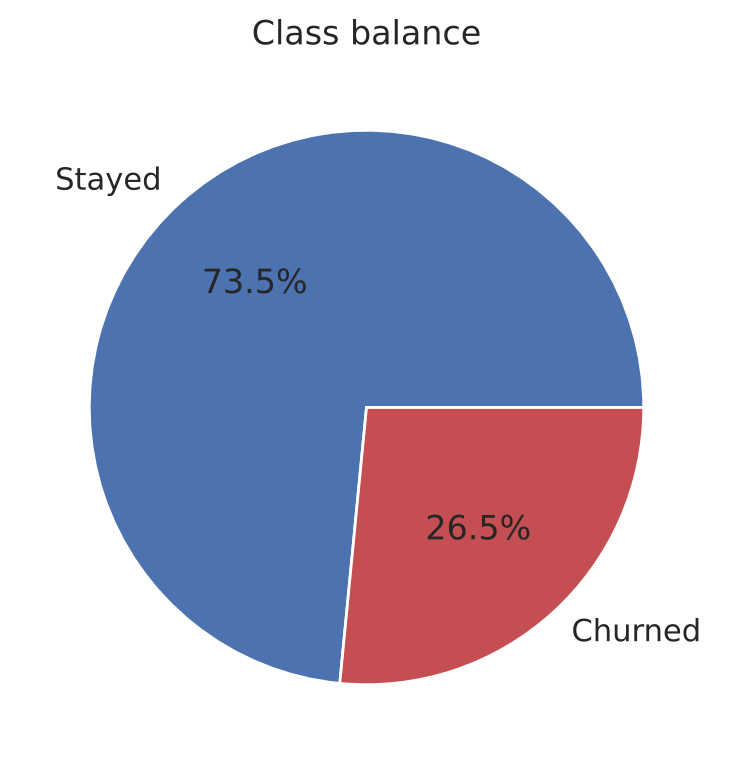

In [5]:
churn_rate = df["Churn"].mean()
print(f"Overall churn rate: {churn_rate:.1%}")
df["Churn"].value_counts().rename({0: "Stayed", 1: "Churned"}).plot.pie(
    autopct="%1.1f%%", colors=["#4C72B0", "#C44E52"], figsize=(4.5, 4.5), ylabel="")
plt.title("Class balance")
plt.show()

The classes are **imbalanced** (about 27% churn). Accuracy alone can mislead here, so we also track **recall, F1 and ROC-AUC**.

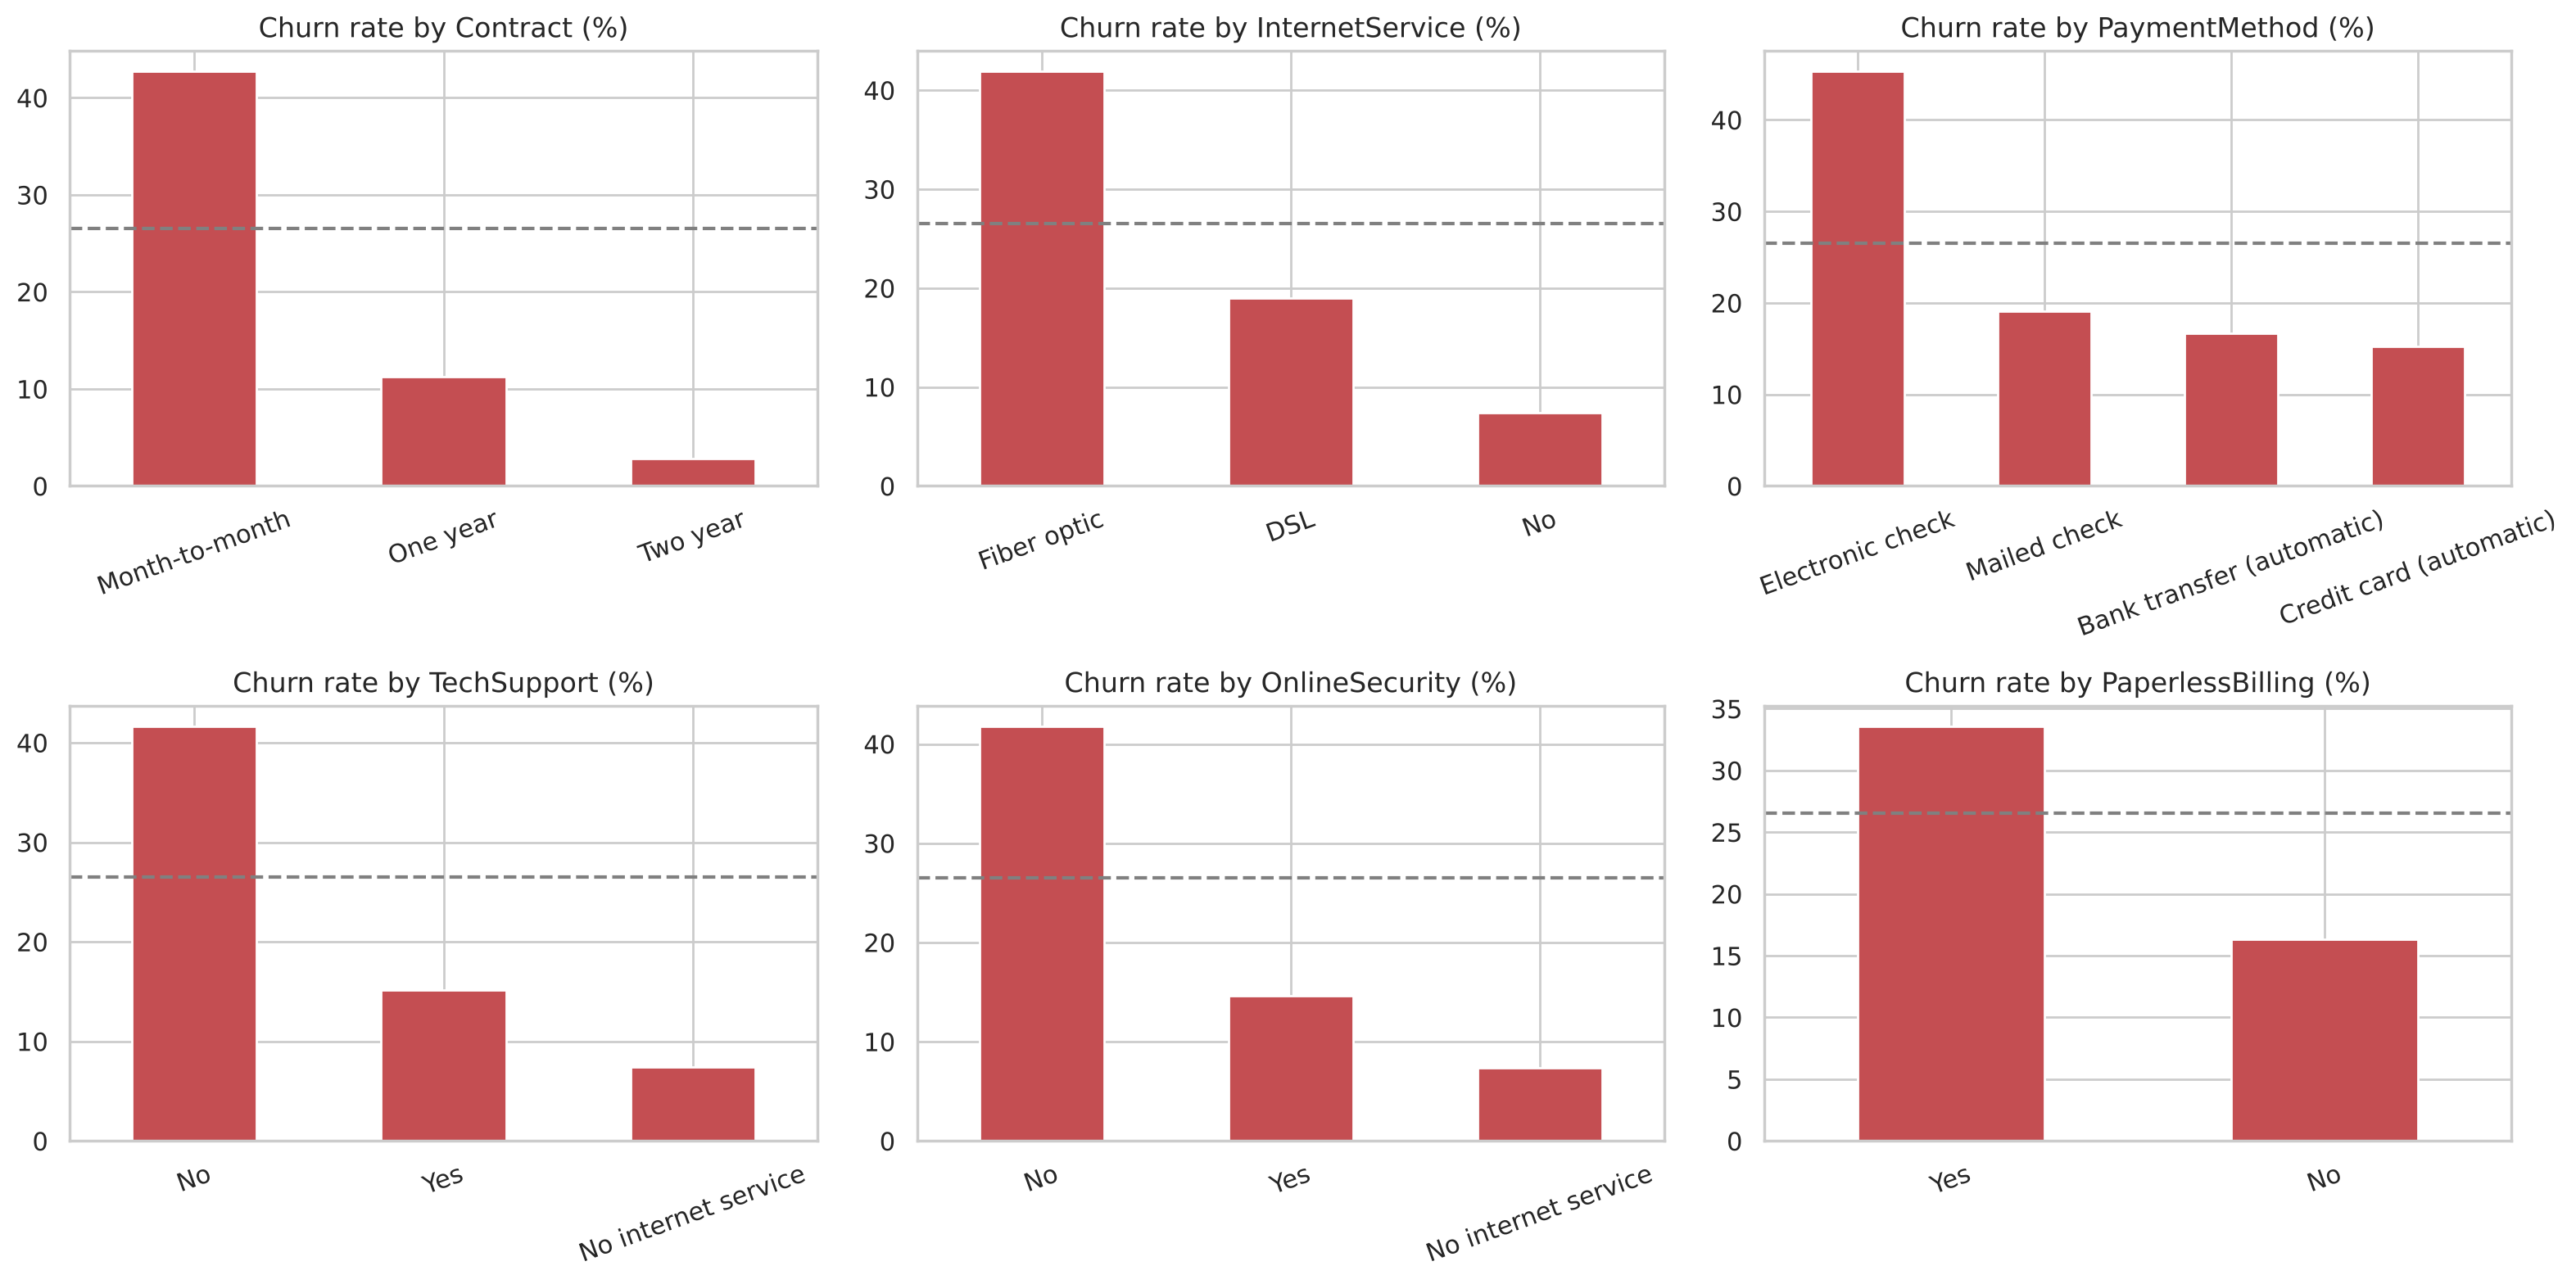

In [6]:
# Churn rate across the key categorical features
cat_view = ["Contract", "InternetService", "PaymentMethod", "TechSupport",
            "OnlineSecurity", "PaperlessBilling"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cat_view):
    rates = df.groupby(col)["Churn"].mean().sort_values(ascending=False) * 100
    rates.plot.bar(ax=ax, color="#C44E52")
    ax.axhline(churn_rate * 100, ls="--", color="grey")
    ax.set_title(f"Churn rate by {col} (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

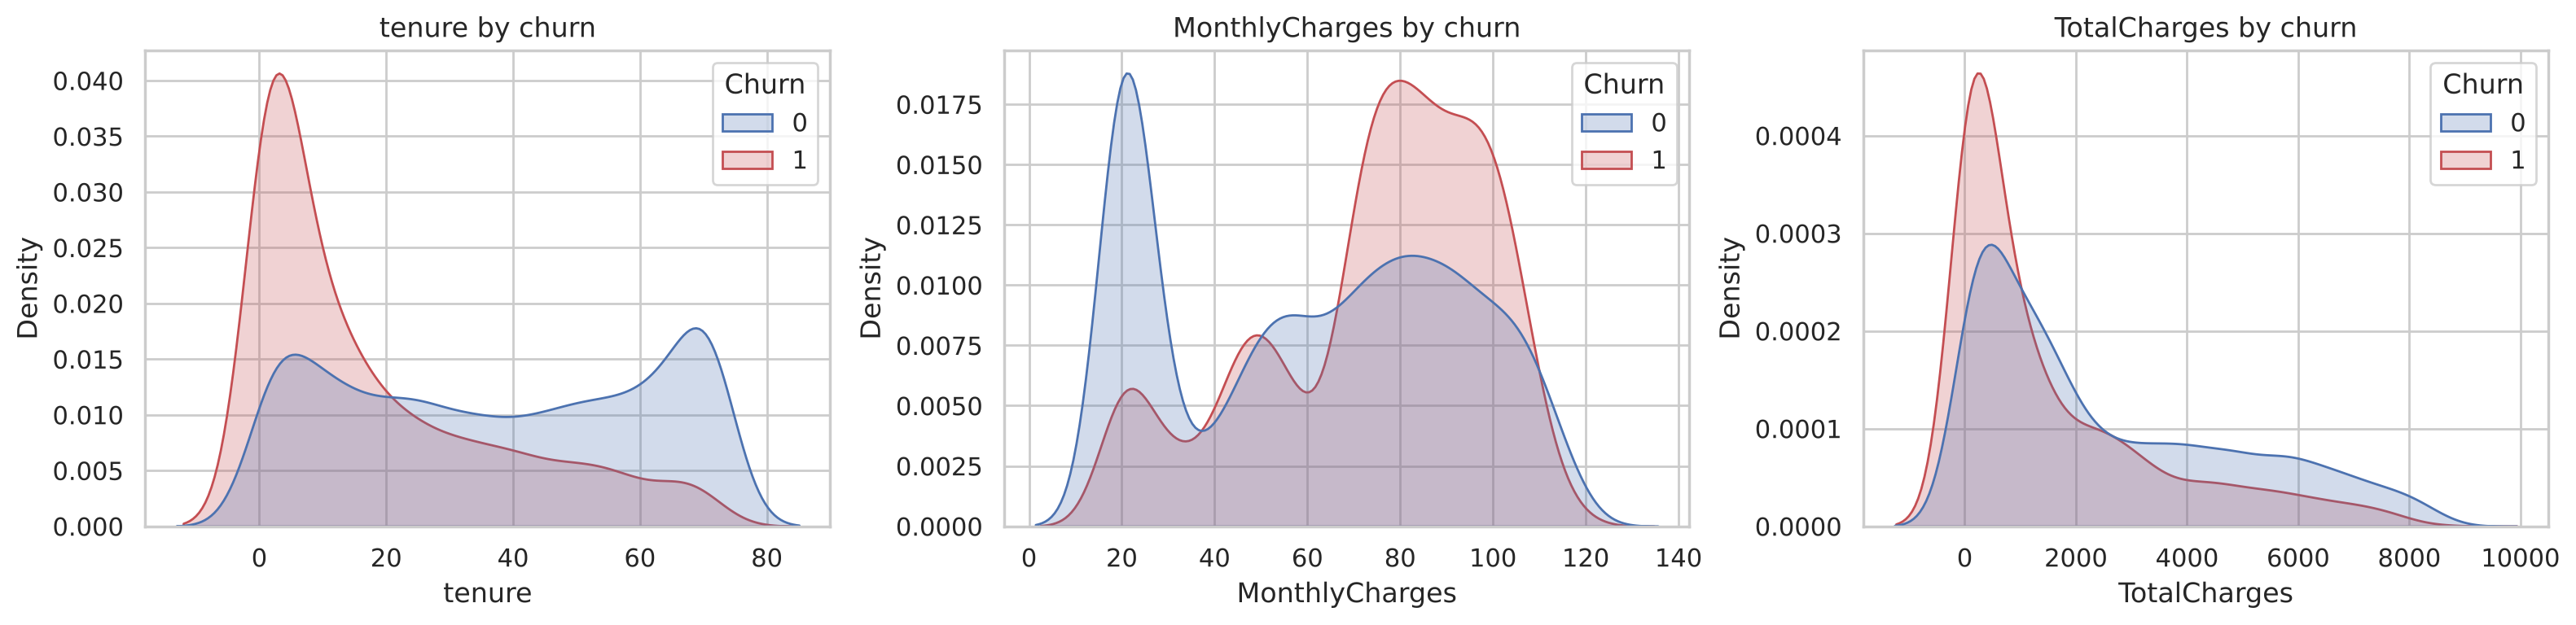

In [7]:
# Numeric features: distributions split by churn
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.kdeplot(data=df, x=col, hue="Churn", fill=True, common_norm=False, ax=ax,
                palette={0: "#4C72B0", 1: "#C44E52"})
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.show()

**EDA observations**
- **Month-to-month** contracts churn far more than one- or two-year contracts.
- **Fiber optic** users, **electronic check** payers, and customers **without tech support or online security** churn more.
- Churners usually have **short tenure** and **higher monthly charges**.

## 4. Feature engineering and encoding

In [8]:
# New features that capture customer behaviour
service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["NumServices"] = (df[service_cols] == "Yes").sum(axis=1) + (df["InternetService"] != "No")
df["AvgMonthlySpend"] = np.where(df["tenure"] > 0, df["TotalCharges"] / df["tenure"], df["MonthlyCharges"])
df["IsNewCustomer"] = (df["tenure"] <= 6).astype(int)

# One-hot encode categorical columns (drop_first avoids redundant columns)
cat_cols = df.select_dtypes(include="object").columns.tolist()
X = pd.get_dummies(df.drop(columns="Churn"), columns=cat_cols, drop_first=True, dtype=int)
y = df["Churn"]
print("Feature matrix shape:", X.shape)

Feature matrix shape: (7043, 33)


In [9]:
# Train/test split (stratified keeps the same churn ratio in both sets)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (5634, 33)  Test: (1409, 33)


## 5. Feature selection
We use two methods, fitted on the **training data only** to avoid data leakage:
1. **Mutual information:** a filter method that scores how much each feature tells us about churn.
2. **Recursive Feature Elimination with cross-validation (RFECV):** a wrapper method that repeatedly drops the weakest feature and keeps the set with the best cross-validated score.

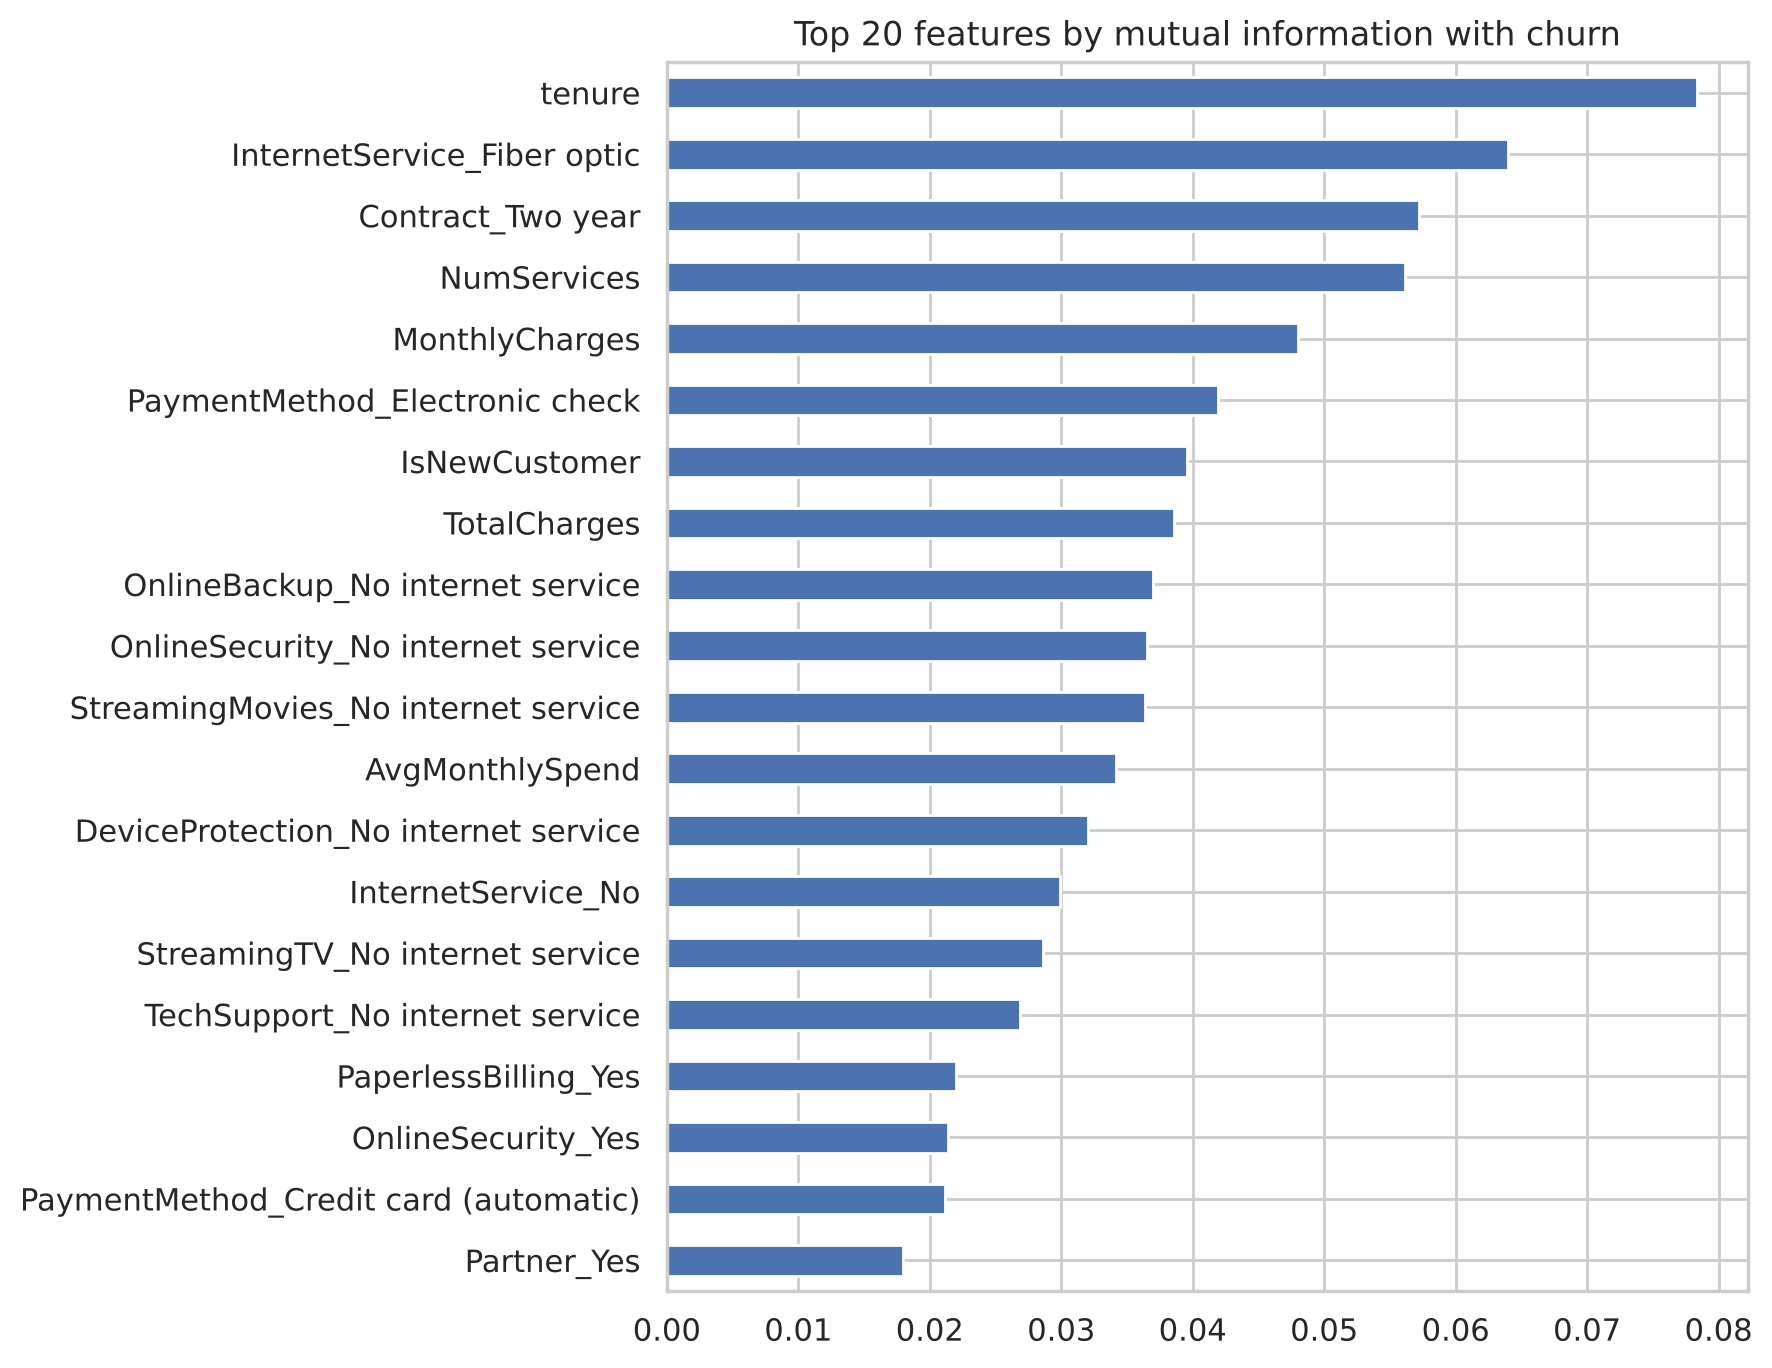

In [10]:
mi = pd.Series(mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE),
               index=X_train.columns).sort_values(ascending=False)
mi.head(20).sort_values().plot.barh(figsize=(9, 7), color="#4C72B0")
plt.title("Top 20 features by mutual information with churn")
plt.tight_layout()
plt.show()

RFECV kept 25 of 33 features


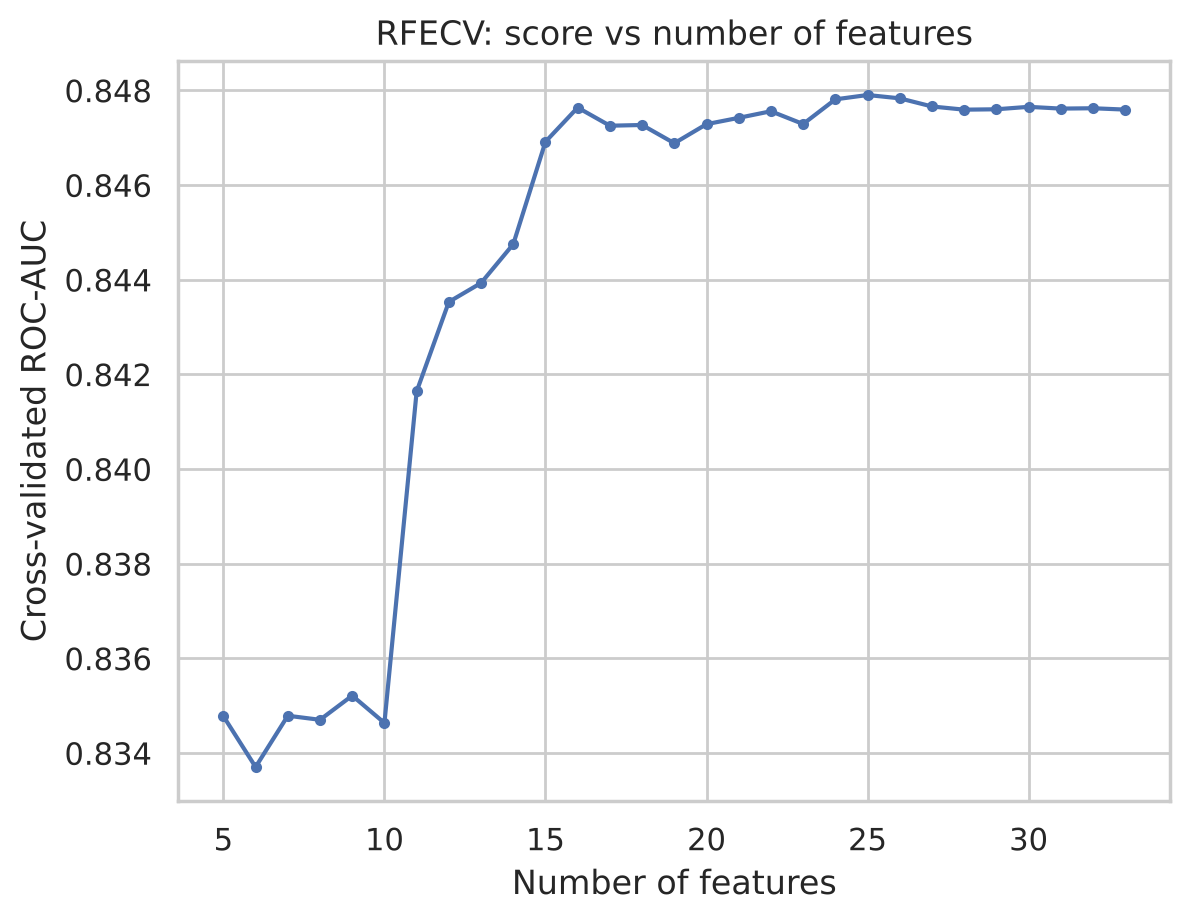

Selected features: ['tenure', 'MonthlyCharges', 'TotalCharges', 'NumServices', 'AvgMonthlySpend', 'IsNewCustomer', 'Dependents_Yes', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Electronic check']


In [11]:
# RFECV with a scaled logistic regression as the estimator
scaler = StandardScaler().fit(X_train)
rfecv = RFECV(LogisticRegression(max_iter=2000), step=1, scoring="roc_auc",
              cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), min_features_to_select=5)
rfecv.fit(scaler.transform(X_train), y_train)

selected = X_train.columns[rfecv.support_].tolist()
print(f"RFECV kept {len(selected)} of {X_train.shape[1]} features")
scores = rfecv.cv_results_["mean_test_score"]
plt.plot(range(5, 5 + len(scores)), scores, marker="o", ms=3)
plt.xlabel("Number of features")
plt.ylabel("Cross-validated ROC-AUC")
plt.title("RFECV: score vs number of features")
plt.show()
print("Selected features:", selected)

In [12]:
X_train_sel, X_test_sel = X_train[selected], X_test[selected]

## 6. Model training
We compare three models of increasing complexity using **5-fold stratified cross-validation** on the training set:
- **Logistic Regression:** simple and interpretable baseline (with `class_weight="balanced"` to handle the imbalance)
- **Random Forest:** an ensemble of decision trees
- **Gradient Boosting:** trees built one after another, each correcting the previous one's errors

In [13]:
models = {
    "Logistic Regression": Pipeline([("scale", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    res = cross_validate(model, X_train_sel, y_train, cv=cv,
                         scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    cv_rows.append({"model": name, **{m: res[f"test_{m}"].mean()
                                      for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]}})
cv_table = pd.DataFrame(cv_rows).set_index("model").round(3)
cv_table

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.752,0.522,0.797,0.631,0.848
Random Forest,0.766,0.542,0.757,0.632,0.843
Gradient Boosting,0.801,0.666,0.505,0.574,0.846


## 7. Model evaluation on the held-out test set

In [14]:
test_rows, fitted = [], {}
for name, model in models.items():
    model.fit(X_train_sel, y_train)
    fitted[name] = model
    pred = model.predict(X_test_sel)
    proba = model.predict_proba(X_test_sel)[:, 1]
    test_rows.append({"model": name, "accuracy": accuracy_score(y_test, pred),
                      "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                      "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, proba)})
test_table = pd.DataFrame(test_rows).set_index("model").round(3)
test_table

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.743,0.510,0.797,0.622,0.845
Random Forest,0.765,0.540,0.778,0.637,0.840
Gradient Boosting,0.800,0.658,0.513,0.577,0.842


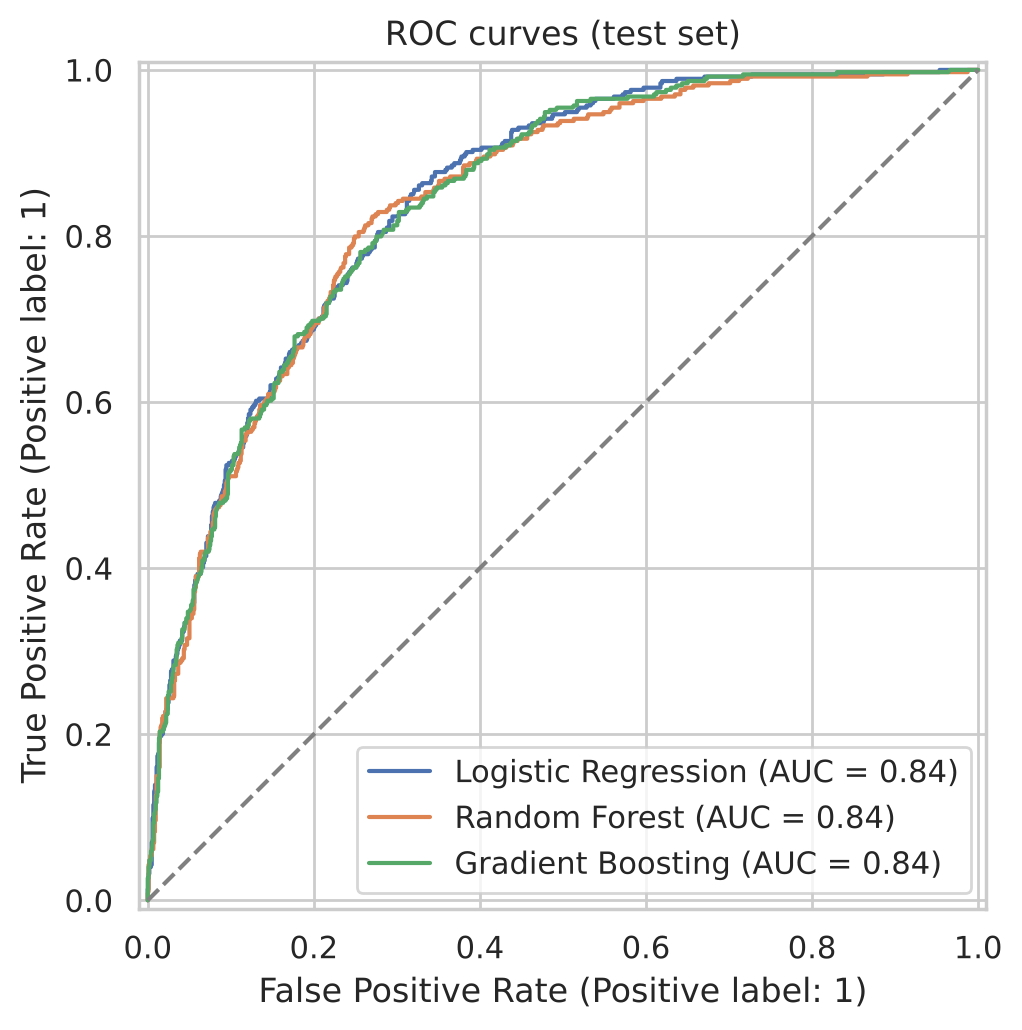

In [15]:
# ROC curves for all models
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, model in fitted.items():
    RocCurveDisplay.from_estimator(model, X_test_sel, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.set_title("ROC curves (test set)")
plt.show()

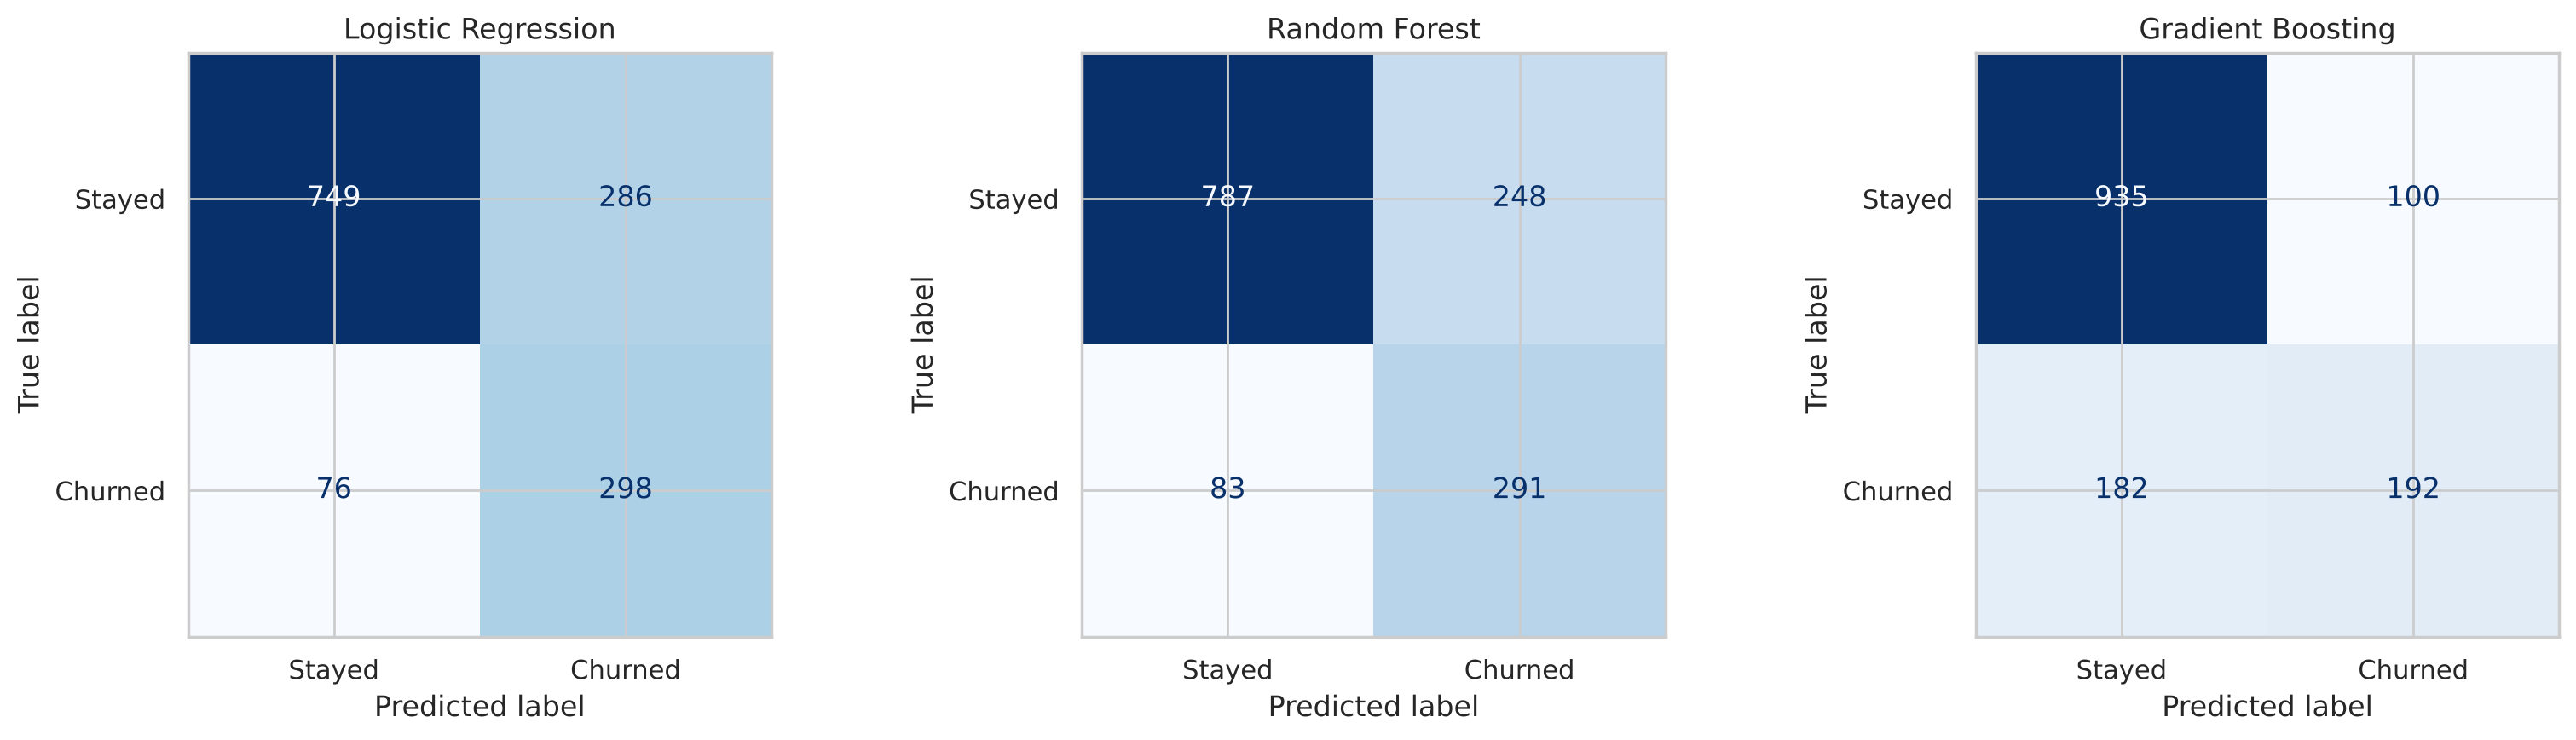

In [16]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, model) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test_sel, y_test, ax=ax, cmap="Blues",
                                          display_labels=["Stayed", "Churned"], colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 8. Hyperparameter tuning
We tune the model with the best cross-validated **ROC-AUC**, using a grid search.

In [17]:
best_name = cv_table["roc_auc"].idxmax()
print("Best model by CV ROC-AUC:", best_name)

grids = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10]},
    "Random Forest": {"n_estimators": [200, 400], "max_depth": [None, 8, 12], "min_samples_leaf": [3, 5, 10]},
    "Gradient Boosting": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [2, 3]},
}
search = GridSearchCV(models[best_name], grids[best_name], scoring="roc_auc", cv=cv, n_jobs=-1)
search.fit(X_train_sel, y_train)
print("Best parameters:", search.best_params_)
print(f"Best CV ROC-AUC: {search.best_score_:.3f}")

final_model = search.best_estimator_
final_pred = final_model.predict(X_test_sel)
final_proba = final_model.predict_proba(X_test_sel)[:, 1]
print(f"\nTest ROC-AUC of tuned model: {roc_auc_score(y_test, final_proba):.3f}\n")
print(classification_report(y_test, final_pred, target_names=["Stayed", "Churned"]))

Best model by CV ROC-AUC: Logistic Regression


Best parameters: {'clf__C': 0.1}
Best CV ROC-AUC: 0.848

Test ROC-AUC of tuned model: 0.844

              precision    recall  f1-score   support

      Stayed       0.91      0.72      0.80      1035
     Churned       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



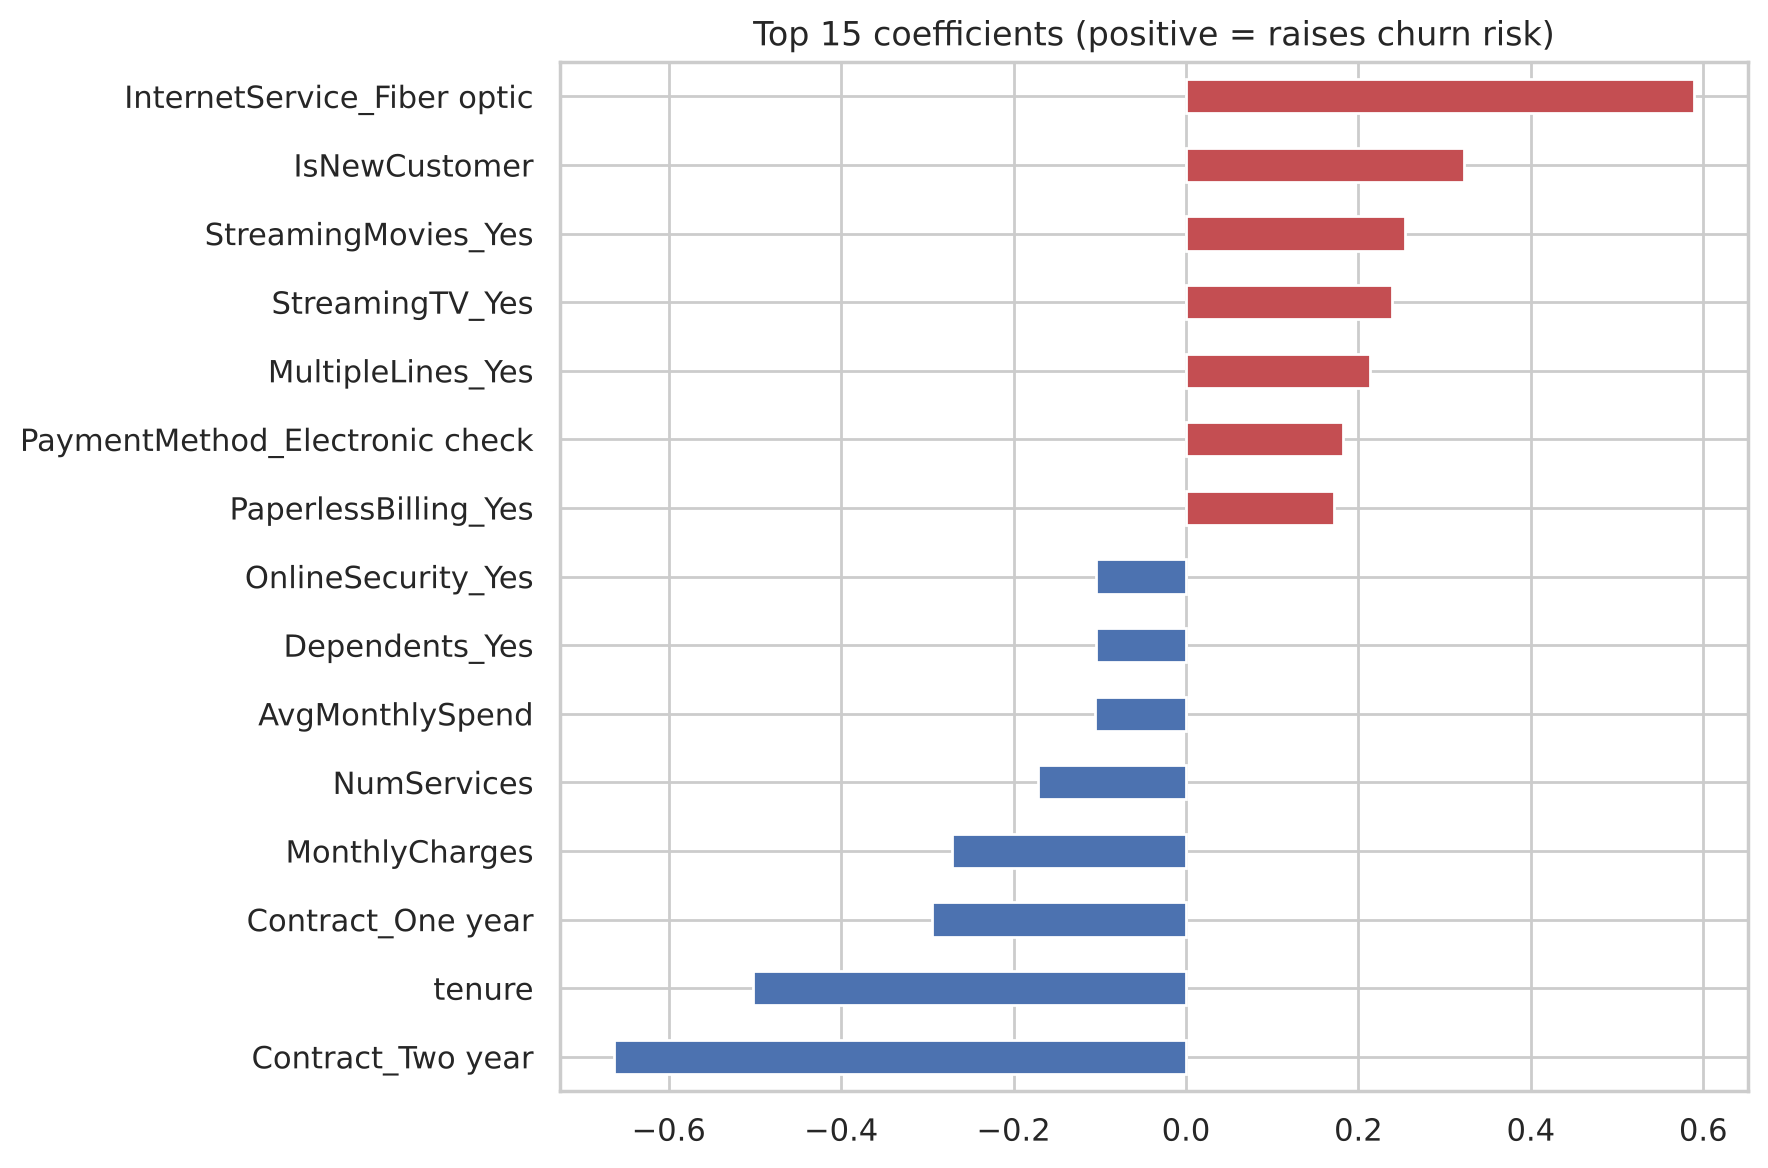

In [18]:
# Which features drive the predictions?
if best_name == "Logistic Regression":
    coefs = pd.Series(final_model.named_steps["clf"].coef_[0], index=selected)
    imp = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)
    title = "Top 15 coefficients (positive = raises churn risk)"
else:
    imp = pd.Series(final_model.feature_importances_, index=selected).sort_values(ascending=False).head(15)
    title = "Top 15 feature importances"
imp.sort_values().plot.barh(figsize=(9, 6), color=["#C44E52" if v > 0 else "#4C72B0" for v in imp.sort_values()])
plt.title(title)
plt.tight_layout()
plt.show()

In [19]:
# Save the final model and the list of features it expects
joblib.dump({"model": final_model, "features": selected}, "churn_model.joblib")
print("Model saved to churn_model.joblib")

# Example: score the 5 test customers most likely to churn
risk = pd.DataFrame({"churn_probability": final_proba, "actual": y_test.values}, index=X_test.index)
risk.sort_values("churn_probability", ascending=False).head()

Model saved to churn_model.joblib


,churn_probability,actual
3380,0.956361,1
6866,0.956178,1
3727,0.953720,1
2797,0.952696,1
3956,0.947643,1


## 9. Business insights and recommendations

**Model results**
- All three models clearly beat random guessing (ROC-AUC 0.5). The tuned best model reaches a test **ROC-AUC of about 0.84**, which means it ranks churners above non-churners well.
- The class-balanced Logistic Regression catches most churners (high **recall**), at the cost of some false alarms. For retention campaigns this is usually the right trade-off: a missed churner is a lost customer, while a false alarm only costs a discount offer.
- Feature selection (RFECV) removed redundant one-hot columns without losing accuracy, which makes the model simpler.

**What drives churn**
- **Contract type** is the strongest signal (the largest model coefficient is for the two-year contract). Month-to-month customers churn far more than customers on 1- or 2-year contracts.
- **Short tenure**: new customers (first 6 months) are the most at risk.
- **Fiber optic** internet and **electronic check** payment are linked to higher churn.
- In the EDA, customers **without Tech Support / Online Security** leave more often. Paying for **streaming add-ons** on top of fiber also raises the predicted risk.

**Recommendations**
1. Offer discounts or perks to move month-to-month customers onto **annual contracts**.
2. Run an **onboarding programme** for the first 6 months (welcome calls, setup help).
3. Bundle **Tech Support and Online Security** into fiber plans, and review fiber pricing and quality.
4. Encourage **automatic payments** (bank transfer or credit card) instead of electronic checks.
5. Use the saved model to **score customers every month** and send the highest-risk ones to the retention team.

*Exact figures are in the tables above.*